2026-10-27 21:07:39 - INFO - ------- Starting simulation -------
2026-10-27 21:07:39 - INFO - Model: 1D_Conductivity_Radiation
2026-10-27 21:07:39 - INFO - Dimension: 1D
2026-10-27 21:07:39 - INFO - Nodes: 11
2026-10-27 21:07:39 - INFO - Elements: 10
2026-10-27 21:07:39 - INFO - Physics: Heat transfer
2026-10-27 21:07:39 - INFO - ------- Solver configuration -------
2026-10-27 21:07:39 - INFO - Study: Steady state
2026-10-27 21:07:39 - INFO - Type: Nonlinear
2026-10-27 21:07:39 - INFO - Method: Direct
2026-10-27 21:07:39 - INFO - Solver: PARDISO (Parallel Direct Sparse Solver)
2026-10-27 21:07:39 - INFO - ------- Starting Newton-Raphson nonlinear solver -------
2026-10-27 21:07:39 - INFO - Relative tolerance: 1.0e-08, Absolute tolerance: 1.0e-10, Max Number of Iterations: 200
2026-10-27 21:07:39 - INFO - -----------------------------------------------------------
2026-10-27 21:07:39 - INFO - |  Iter  |      ||R||      |  ||R||/||R0||   | Alpha (Step)
2026-10-27 21:07:39 - INFO - ------

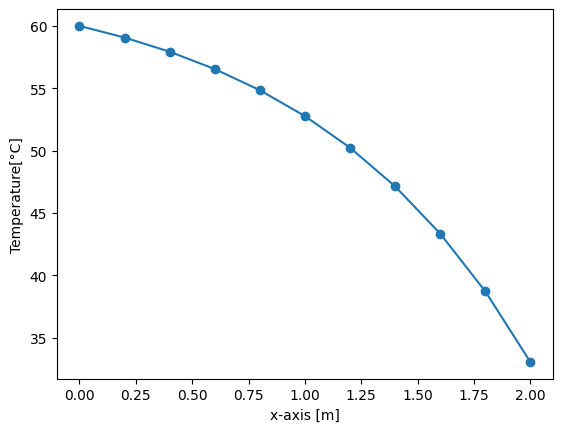

In [1]:
## FEM Simualtion

from Source.Pre_processing.Mesh import Mesh
from Source.core import Model
from Source.Material import material
from Source.Physics.HeatTransfer import ht

from Source.enums import ElementType, ShapeFunctionType, StudyType, ProblemType, SolverType, DirectSolvers

# Define basis functions variables
# e1 = sp.symbols('e1')

PD = 1  # Problem Dimension: 1->1D; 2->2D(!); 3->3D(!)

# Create mesh from linear element

L = 2  # Length size of the domain [m]
NoE = 10  # Number of Elements
MeshType = ElementType.line  # Type of element
shapeFunction = ShapeFunctionType.linear  # Shape function for spatial discretization

Mesh1 = Mesh()
Mesh1.Generate_Mesh(PD, L, NoE, MeshType)
Mesh1.setElementShapeFunction(shapeFunction)

Mesh1.defineBoundary('inlet', 0)
Mesh1.defineBoundary('outlet', NoE) # Hardcoded

Mat1 = material('Aluminio', k = 1, miu=1, rho=1, Cp= 1)

Model1 = Model(name='1D_Conductivity_Radiation', mtype=None, dim=PD, mesh=Mesh1, mat=Mat1, psc=ht)

Model1.physics.addBC_Temperature(id=Mesh1.boundaries['inlet'], T=60)
#Model1.physics.addBC_Convection(Mesh1.boundaries['outlet'], 1, 10)
Model1.physics.addBC_Radiation(Mesh1.boundaries['outlet'], 0.7, 26)
#Model1.physics.addBC_Temperature(id=Mesh1.boundaries['outlet'], T=4.0)

Model1.physics.Convection = True
Model1.physics.Stab = None

Model1.physics.initField('T', 60.0)

options = {'Study': StudyType.steady_state, 'Type': ProblemType.nonlinear, 'Method': SolverType.direct, 'Solver': DirectSolvers.PARDISO}


#solverOptions = {'Study': StudyType.steady_state, 'Type': ProblemType.linear, 'Method': SolverType.direct, 'Solver':'PARDISO'}

Model1.solverConfiguration(**options)

Model1.solve()

Model1.postProcess()